Network and Module Analysis Notebook

This notebook examines Pearson/Spearman agreement, correlation thresholds, edge signs, family enrichment and graph display limits. It reads the locked expression matrix and the latest network-analysis outputs. Rerun pipeline.network_analysis after changing the input matrix.

Setup and load the current analysis outputs

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src/processed/network_analysis.json").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Run preprocessing and pipeline.network_analysis first; network_analysis.json was not found."
    )
PROCESSED = project_root / "src" / "processed"
SRC_ROOT = project_root / "src"
DATA = project_root / "data"
analysis = json.loads((PROCESSED / "network_analysis.json").read_text())
expression = pd.read_parquet(PROCESSED / "muscle_logcpm_corrected_top5000.parquet")
print("Matrix:", expression.shape, "| genes unique:", expression.index.is_unique,
      "| samples unique:", expression.columns.is_unique,
      "| missing values:", int(expression.isna().sum().sum()))

Matrix: (5000, 803) | genes unique: True | samples unique: True | missing values: 0


Compare Pearson and Spearman

Both methods use the same 5,000 genes and 803 samples. This table compares their pairwise values, selected edges and leading hubs.

In [2]:
comparison = analysis["method_comparison"]
method_comparison = pd.DataFrame([
    ("Correlation across all gene-pair values", comparison["pearson_spearman_pairwise_correlation"]),
    ("Top 100 absolute pairs Jaccard", comparison["top_100_absolute_edges_jaccard"]),
    ("Top 1,000 absolute pairs Jaccard", comparison["top_1000_absolute_edges_jaccard"]),
    ("Thresholded network edge Jaccard at 0.70", comparison["thresholded_network_edge_jaccard"]),
    ("Top 15 hub ID Jaccard at 0.70", comparison["top_15_hub_id_jaccard"]),
], columns=["Comparison", "Agreement"])
display(method_comparison.round(3))

,Comparison,Agreement
0,Correlation across all gene-pair values,0.990
1,Top 100 absolute pairs Jaccard,0.613
2,"Top 1,000 absolute pairs Jaccard",0.692
3,Thresholded network edge Jaccard at 0.70,0.550
4,Top 15 hub ID Jaccard at 0.70,0.667


Observation: Correlation method

Pearson and Spearman values agree closely overall, but their strongest edge and hub sets overlap less. Pearson is the primary analysis and Spearman is a useful sensitivity comparison.

Review the threshold sweep

The sweep compares network size and connectivity with split-half overlap and same-family enrichment.

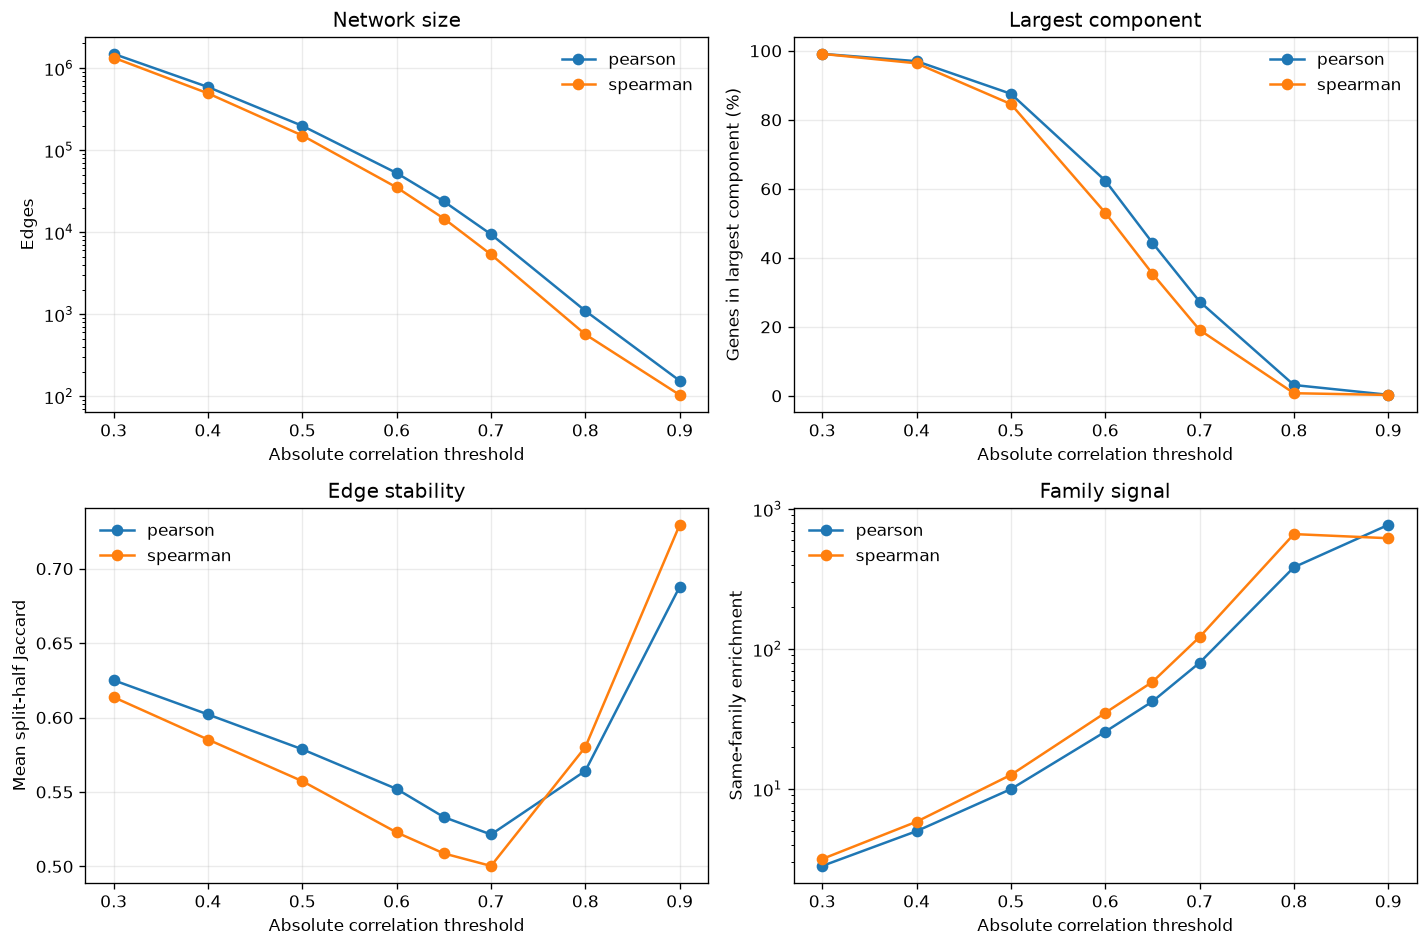

In [3]:
threshold_rows = []
for method, result in analysis["methods"].items():
    for row in result["threshold_metrics"]:
        threshold_rows.append({"method": method, **row})
thresholds = pd.DataFrame(threshold_rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for method, group in thresholds.groupby("method"):
    group = group.sort_values("threshold")
    axes[0, 0].plot(group["threshold"], group["edges"], marker="o", label=method)
    axes[0, 1].plot(group["threshold"], group["largest_component_pct"], marker="o", label=method)
    axes[1, 0].plot(group["threshold"], group["split_half_jaccard"], marker="o", label=method)
    axes[1, 1].plot(group["threshold"], group["same_family_edge_enrichment"], marker="o", label=method)
axes[0, 0].set(yscale="log", xlabel="Absolute correlation threshold", ylabel="Edges", title="Network size")
axes[0, 1].set(xlabel="Absolute correlation threshold", ylabel="Genes in largest component (%)", title="Largest component")
axes[1, 0].set(xlabel="Absolute correlation threshold", ylabel="Mean split-half Jaccard", title="Edge stability")
axes[1, 1].set(yscale="log", xlabel="Absolute correlation threshold", ylabel="Same-family enrichment", title="Family signal")
for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Higher cutoffs produce smaller networks and smaller largest components. Split-half overlap also changes across cutoffs, so a higher correlation alone does not guarantee a more stable network.

As the cutoff rises, the network gets smaller and its largest connected group shrinks. Split-half overlap also changes across cutoffs, so a higher cutoff is not automatically a better network.

Compare the 0.65 display network with the 0.70 sensitivity checkpoint

In [4]:
def threshold_row(method, threshold):
    return next(row for row in analysis["methods"][method]["threshold_metrics"]
                if np.isclose(row["threshold"], threshold))

selected_rows = []
for method in ("pearson", "spearman"):
    for threshold in (0.65, 0.70):
        row = threshold_row(method, threshold)
        selected_rows.append({
            "method": method,
            "threshold": threshold,
            "edges": row["edges"],
            "isolated genes": row["isolated_genes"],
            "largest component (%)": round(row["largest_component_pct"], 1),
            "split-half Jaccard": round(row["split_half_jaccard"], 3),
            "edges in one permuted null": row["null_edges"],
        })
display(pd.DataFrame(selected_rows))

,method,threshold,edges,isolated genes,largest component (%),split-half Jaccard,edges in one permuted null
0,pearson,0.65,23751,2394,44.4,0.533,0
1,pearson,0.70,9443,3161,27.3,0.521,0
2,spearman,0.65,14687,2763,35.4,0.509,0
3,spearman,0.70,5357,3486,19.1,0.500,0


Observation: 0.65 and 0.70

At 0.65, the Pearson network has 23,751 edges and a largest component containing 44.4% of genes. At 0.70, it has 9,443 edges and a 27.3% largest component. This supports 0.65 as the denser display network; the comparison does not establish a uniquely optimal cutoff.

Permutation check

The current report uses one shuffled-data null per method and finds no edges at these cutoffs. One shuffle is a rough check, not a reliable estimate of the false-edge rate.

The production script reports zero edges at these cutoffs in one shuffled-data null per method. That is a useful rough check, but one shuffle is not enough to estimate a reliable false-edge rate.

Check the positive and negative edges

Edges are selected by absolute correlation, so both signs should be retained. The visualization uses solid blue lines for positive values and dashed orange lines for negative values.

sign,positive,negative
method,,
pearson,23116,635
spearman,14413,274


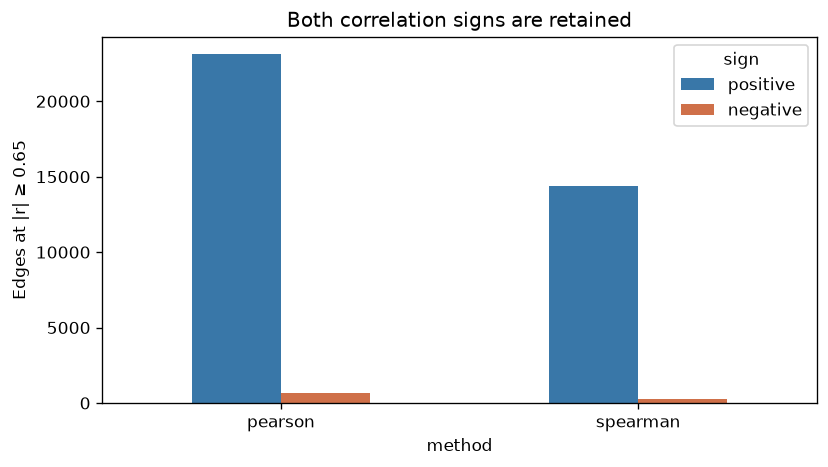

In [5]:
sign_counts = []
for method in ("pearson", "spearman"):
    path = PROCESSED / f"network_edges_{method}_abs0.65.parquet"
    edges = pd.read_parquet(path)
    sign_counts.extend([
        {"method": method, "sign": "positive", "edges": int((edges["r"] > 0).sum())},
        {"method": method, "sign": "negative", "edges": int((edges["r"] < 0).sum())},
    ])
sign_counts = pd.DataFrame(sign_counts)
sign_table = sign_counts.pivot(index="method", columns="sign", values="edges").reindex(
    columns=["positive", "negative"]
)
display(sign_table)
sign_table.plot(kind="bar", figsize=(7, 4), color=["#3977a8", "#cf7049"])
plt.ylabel("Edges at |r| ≥ 0.65")
plt.title("Both correlation signs are retained")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Observation: Edge signs

Both positive and negative edges are present in the saved networks. The visualization distinguishes their signs, so negative relationships are not discarded.

Check the family-enrichment summary

The code groups genes by selected symbol prefixes. It calculates the observed same-family edge fraction, the background fraction among all possible gene pairs, and their ratio. These are descriptive results; the prefixes do not prove the function of a gene or edge.

In [6]:
family_rows = []
for method, result in analysis["methods"].items():
    for row in result["threshold_metrics"]:
        if row["threshold"] in (0.65, 0.70):
            family_rows.append({
                "method": method,
                "threshold": row["threshold"],
                "same-family edges": row["same_family_edges"],
                "observed fraction": round(row["same_family_edge_enrichment"] * result["same_family_background_fraction"], 4),
                "observed enrichment": round(row["same_family_edge_enrichment"], 2),
                "background fraction": round(result["same_family_background_fraction"], 4),
            })
display(pd.DataFrame(family_rows))

,method,threshold,same-family edges,observed fraction,observed enrichment,background fraction
0,pearson,0.65,109,0.0046,42.20,0.0001
1,pearson,0.70,82,0.0087,79.86,0.0001
2,spearman,0.65,93,0.0063,58.23,0.0001
3,spearman,0.70,71,0.0133,121.88,0.0001


The family labels come from symbol prefixes. Treat the enrichment as a broad pattern, since the prefix rules do not validate each gene-family assignment.

Review visualization display choices

The expression matrix is ordered by corrected-expression variance. The next plot compares heatmaps of the top 50, 100 and 200 genes; these are display sizes, not statistical thresholds.

Rows are ordered by descending corrected-expression variance: True
Top 200 genes span variance ranks 1 through 200.


<ipython-input-1-800ad67a6f1f>:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


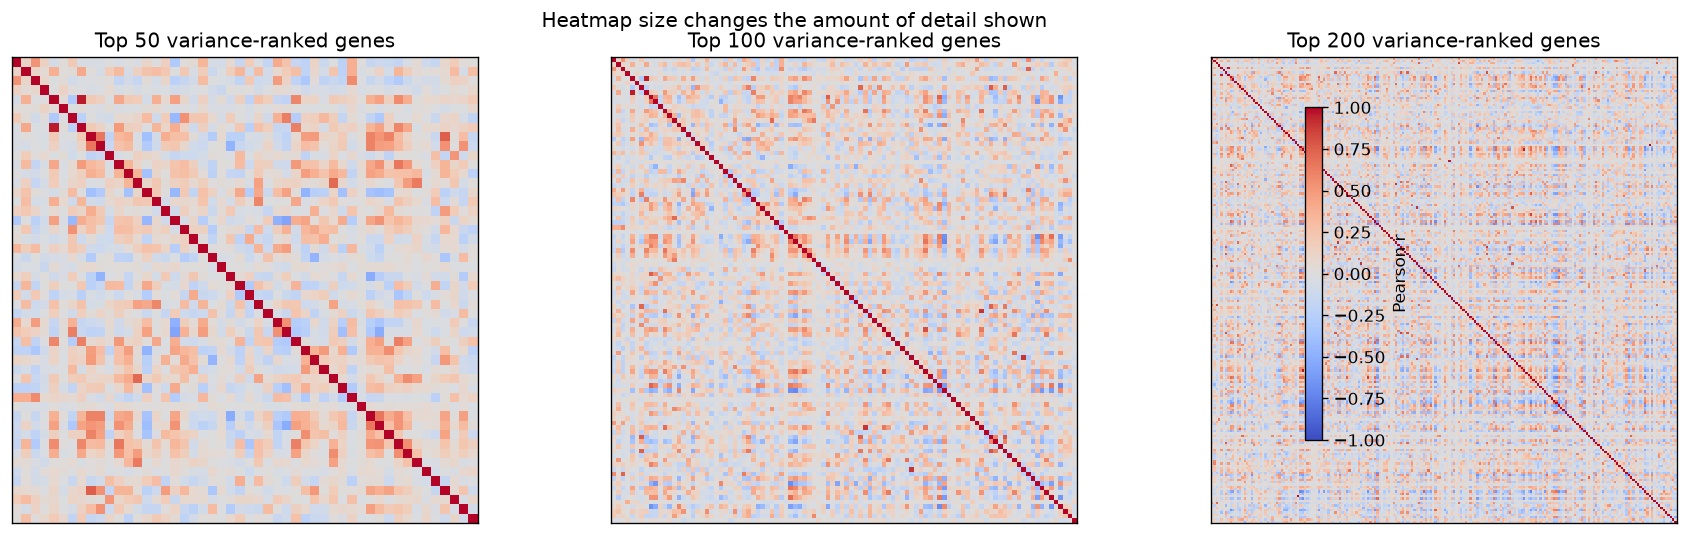

In [7]:
variance = expression.var(axis=1, ddof=1)
ranked = bool((variance.to_numpy()[:-1] >= variance.to_numpy()[1:]).all())
print("Rows are ordered by descending corrected-expression variance:", ranked)
print("Top 200 genes span variance ranks 1 through 200.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, n_genes in zip(axes, (50, 100, 200)):
    genes = expression.index[:n_genes]
    matrix = expression.loc[genes].T.corr().to_numpy()
    image = ax.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
    ax.set(title=f"Top {n_genes} variance-ranked genes", xticks=[], yticks=[])
fig.colorbar(image, ax=axes, label="Pearson r", shrink=0.8)
fig.suptitle("Heatmap size changes the amount of detail shown")
fig.tight_layout()
plt.show()

Observation: Heatmap size

The ordering is reproducible because the matrix rows are variance-ranked. The data do not select 200 as an optimal heatmap size; it is a display limit.

Review the local hub graph display

Leading Pearson hub: TIMP2 (ENSG00000035862)
Degree in full network: 241
Displayed neighbor limits: {15: 15, 30: 30, 50: 50}


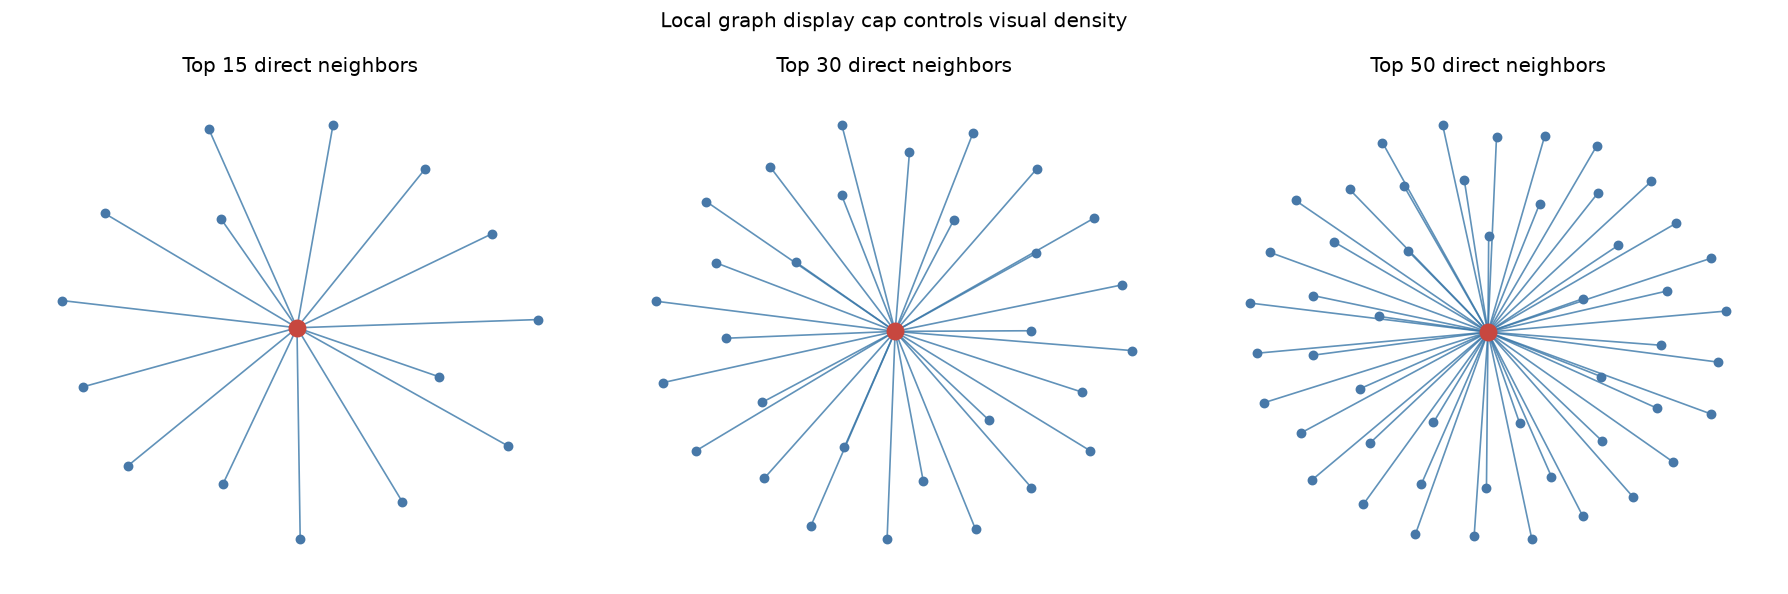

In [8]:
edges = pd.read_parquet(PROCESSED / "network_edges_pearson_abs0.65.parquet")
hubs = pd.read_parquet(PROCESSED / "network_hubs_pearson_abs0.65.parquet")
graph = nx.Graph()
graph.add_nodes_from(expression.index.astype(str))
graph.add_edges_from(
    (str(row.gene_1), str(row.gene_2), {"r": float(row.r), "weight": float(row.weight)})
    for row in edges.itertuples(index=False)
)
center = str(hubs.iloc[0]["gene_id"])
center_symbol = hubs.iloc[0]["symbol"]
neighbors = sorted(graph.neighbors(center), key=lambda node: graph[center][node]["weight"], reverse=True)
print("Leading Pearson hub:", center_symbol, f"({center})")
print("Degree in full network:", graph.degree(center))
print("Displayed neighbor limits:", {n: min(n, len(neighbors)) for n in (15, 30, 50)})

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, limit in zip(axes, (15, 30, 50)):
    selected = neighbors[:limit]
    display_graph = nx.Graph()
    display_graph.add_nodes_from([center, *selected])
    display_graph.add_edges_from((center, node, graph[center][node]) for node in selected)
    positions = nx.spring_layout(display_graph, seed=42, weight="weight", iterations=100)
    positive = [(u, v) for u, v, data in display_graph.edges(data=True) if data["r"] >= 0]
    negative = [(u, v) for u, v, data in display_graph.edges(data=True) if data["r"] < 0]
    nx.draw_networkx_edges(display_graph, positions, edgelist=positive, edge_color="#3977a8", ax=ax, alpha=0.8)
    nx.draw_networkx_edges(display_graph, positions, edgelist=negative, edge_color="#cf7049", style="dashed", ax=ax, alpha=0.8)
    nx.draw_networkx_nodes(display_graph, positions, nodelist=selected, node_size=24,
                           node_color="#4778a8", ax=ax)
    nx.draw_networkx_nodes(display_graph, positions, nodelist=[center], node_size=95,
                           node_color="#c7473f", ax=ax)
    ax.set_title(f"Top {limit} direct neighbors")
    ax.axis("off")
fig.suptitle("Local graph display cap controls visual density")
fig.tight_layout()
plt.show()

Observation: Local graph size

The leading Pearson hub has many neighbors in the full network. The graph shows 30 of its strongest links to keep the local view readable; 30 is a display choice, not a biological cutoff.

Summary

0.65: denser than 0.70 in this dataset and used for the primary display.
0.70: a stricter comparison point.
Pearson and Spearman: similar overall correlation values, with partial overlap among selected edges and hubs.
Positive and negative edges: both are retained and shown with different line styles.
Heatmap and local graph sizes: chosen for readability.
Permutation null: one shuffle is insufficient for a precise false-edge estimate.

Final analysis: detect and characterize modules

This stage uses the locked 5,000 genes × 803 samples corrected expression matrix and the Pearson edge table. Modules use positive Pearson edges with r ≥ 0.65 and weighted Louvain at resolution 1.0, chosen in the notebook. Communities with fewer than 10 genes and isolates receive the M0 label.

At this setting, 2,255 genes are assigned to 21 reportable modules and 2,745 receive M0. Of assigned genes, 458 match another module eigengene more strongly than their own and 455 have |kME| < 0.5. The module summary reports size, within-module connectivity, boundary share, and top hubs. These are network summaries, not evidence that a hub regulates other genes.

Figures from the module visualization stage:

![Module expression heatmap](../src/processed/module_visualizations/module_expression_heatmap.png)

![Module sizes](../src/processed/module_visualizations/module_sizes.png)

![Module eigengene similarity](../src/processed/module_visualizations/module_eigengene_similarity.png)

![Module eigengene patterns](../src/processed/module_visualizations/module_expression_patterns.png)

![Module enrichment dot plot](../src/processed/module_visualizations/enrichment_dotplot_top_terms.png)

![Representative module networks](../src/processed/module_visualizations/representative_module_networks.png)

![Module top hubs](../src/processed/module_visualizations/module_top_hubs.png)

In [ ]:
import json
import subprocess
import sys
import pandas as pd

module_run = subprocess.run(
    [sys.executable, "-m", "pipeline.module_analysis"],
    cwd=SRC_ROOT, check=True, capture_output=True, text=True,
)
result = json.loads((PROCESSED / "module_analysis.json").read_text())
selected = result["selected_resolution"]
print("Input: 5,000 genes x 803 samples; positive Pearson edges with r >= 0.65; weighted Louvain, resolution 1.0, seed 42.")
print(
    f"{selected['genes_assigned_to_modules']:,} genes in {len(selected['module_ids'])} modules; "
    f"M0={selected['genes_in_m0']:,}; boundary genes={selected['boundary_genes']:,}; "
    f"weak kME < 0.5={selected['weak_kme_genes']:,}; "
    f"maximum |eigengene correlation|={selected['maximum_abs_module_eigengene_correlation']:.3f}."
)
module_summary = pd.read_parquet(
    PROCESSED / f"module_summary_louvain_res{selected['resolution']:.1f}.parquet"
)
module_summary["top_hubs"] = module_summary["top_hubs"].map(
    lambda items: ", ".join(str(item["symbol"]) for item in items)
)
module_summary = module_summary[[
    "module_id", "n_genes", "mean_intramodule_degree", "mean_r_within_module",
    "boundary_fraction", "top_hubs",
]]
print("\nModule characterization:")
print(module_summary.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


Module results

The locked module assignments and characterization tables feed the enrichment analysis below.

Module analysis: threshold and covariate audit

The cutoff keeps positive gene links. Louvain groups genes using those links. Negative links are left out. We compare cutoffs, but there is no known correct answer.

In [ ]:
# Compare module partitions across positive-edge correlation cutoffs.
expression = pd.read_parquet(PROCESSED / "muscle_logcpm_corrected_top5000.parquet")
values = expression.to_numpy(dtype=np.float64, copy=True)
values -= values.mean(axis=1, keepdims=True)
values /= values.std(axis=1, ddof=1, keepdims=True)
correlation = values @ values.T / (values.shape[1] - 1)
np.clip(correlation, -1, 1, out=correlation)
np.fill_diagonal(correlation, 1)
i, j = np.triu_indices(len(expression), k=1)
r = correlation[i, j]
genes = expression.index.astype(str).to_numpy()
rows = []
for cutoff in [0.55, 0.60, 0.65, 0.70, 0.75, 0.80]:
    keep = r >= cutoff
    graph = nx.Graph()
    graph.add_nodes_from(genes)
    graph.add_weighted_edges_from((genes[a], genes[b], float(x)) for a, b, x in zip(i[keep], j[keep], r[keep]))
    communities = nx.community.louvain_communities(graph, weight="weight", resolution=1.0, seed=42)
    sizes = np.array([len(group) for group in communities])
    large = sizes >= 10
    rows.append({"r cutoff": cutoff, "positive edges": int(keep.sum()),
                 "Louvain Q": nx.community.modularity(graph, communities, weight="weight"),
                 "reportable modules": int(large.sum()), "genes in modules ≥10": int(sizes[large].sum()),
                 "largest module": int(sizes.max()), "isolated genes": int((sizes == 1).sum())})
print(pd.DataFrame(rows).to_string(index=False, formatters={"Louvain Q": "{:.3f}".format}))

 r cutoff  positive edges Louvain Q  reportable modules  genes in modules ≥10  largest module  isolated genes
     0.55           98296     0.537                  12                  3857            1177             976
     0.60           50161     0.561                  19                  3132             679            1618
     0.65           23116     0.617                  21                  2255             431            2398
     0.70            9338     0.701                  24                  1425             302            3165
     0.75            3295     0.802                  17                   705             158            3854
     0.80            1101     0.903                   9                   287              71            4372


Do the current modules still track measured sample factors?

We checked how sample traits relate to module patterns. Numeric traits use Spearman correlation; categories use η². These checks are descriptive. SMNABTCH has many rare groups, so its results are hard to trust. GTEx defines SMTSISCH as ischemic time and SME2MPRT as End 2 mapping rate.

In [ ]:
# Screen module eigengenes for numeric and categorical sample traits.
eigengenes = pd.read_parquet(PROCESSED / "module_eigengenes_louvain_res1.0.parquet")
metadata = pd.read_parquet(PROCESSED / "muscle_metadata.parquet").reindex(eigengenes.index)
numeric = ["SMTSISCH", "SMRIN", "SMNTRNRT", "SMEXNCRT", "SMGNSDTC", "SMTRSCPT", "SME2MPRT", "SMCHMPRS"]
numeric_data = pd.concat([metadata[numeric].apply(pd.to_numeric, errors="coerce"), eigengenes], axis=1)
correlations = numeric_data.corr(method="spearman").loc[numeric, eigengenes.columns]
rows = []
for trait, values in correlations.abs().iterrows():
    module = values.idxmax()
    rows.append({"trait": trait, "strongest module": module, "max |Spearman r|": values[module],
                 "median |r| across modules": values.median()})
print("Numeric attributes (rank correlation with module eigengenes)")
print(pd.DataFrame(rows).to_string(index=False, formatters={"max |Spearman r|": "{:.3f}".format,
      "median |r| across modules": "{:.3f}".format}))

def eta_squared(groups, eigengene):
    data = pd.DataFrame({"group": groups.astype("string").fillna("Missing"), "y": eigengene}).dropna()
    mean = data["y"].mean()
    total = ((data["y"] - mean) ** 2).sum()
    grouped = data.groupby("group")["y"]
    between = (grouped.size() * (grouped.mean() - mean) ** 2).sum()
    return between / total if total else 0.0

donors = eigengenes.index.astype(str).str.extract(r"^(GTEX-[^-]+)", expand=False)
subjects = pd.read_csv(DATA / "GTEx_Analysis_v8_Annotations_SubjectPhenotypesDS.txt", sep="\t").set_index("SUBJID")
ages = subjects["AGE"].reindex(donors.to_numpy()).astype("string")
categories = {"DTHHRDY": metadata["DTHHRDY"], "SEX": metadata["SEX"],
              "AGE": pd.Series(ages.to_numpy(), index=eigengenes.index),
              "SMCENTER": metadata["SMCENTER"], "SMNABTCHT": metadata["SMNABTCHT"]}
rows = []
for trait, groups in categories.items():
    effects = pd.Series({module: eta_squared(groups, eigengenes[module]) for module in eigengenes})
    module = effects.idxmax()
    rows.append({"trait": trait, "strongest module": module, "max η²": effects[module],
                 "median η² across modules": effects.median(),
                 "levels": groups.astype("string").fillna("Missing").nunique()})
print("\nCategorical attributes (eta-squared with module eigengenes)")
print(pd.DataFrame(rows).to_string(index=False, formatters={"max η²": "{:.3f}".format,
      "median η² across modules": "{:.3f}".format}))
batches = metadata["SMNABTCH"].astype("string").fillna("Missing").value_counts()
print(f"\nSMNABTCH: {len(batches)} levels; {(batches == 1).sum()} singletons; {(batches >= 5).sum()} levels have ≥5 samples.")

Numeric attributes (rank correlation with module eigengenes)
   trait strongest module max |Spearman r| median |r| across modules
SMTSISCH             M002            0.155                     0.039
   SMRIN             M018            0.081                     0.035
SMNTRNRT             M014            0.082                     0.029
SMEXNCRT             M014            0.077                     0.027
SMGNSDTC             M006            0.321                     0.190
SMTRSCPT             M006            0.321                     0.189
SME2MPRT             M018            0.603                     0.029
SMCHMPRS             M011            0.232                     0.035

Categorical attributes (eta-squared with module eigengenes)
    trait strongest module max η² median η² across modules  levels
  DTHHRDY             M002  0.000                    0.000       6
      SEX             M002  0.000                    0.000       2
      AGE             M016  0.035                    0.0

Targeted sensitivity: add SME2MPRT

SME2MPRT had the strongest leftover link to a module. This check adds it to correction and reruns the analysis with the same settings. It tests whether the results change; it does not show that SME2MPRT should be removed.

In [ ]:
from sklearn.metrics import adjusted_rand_score

expression = pd.read_parquet(PROCESSED / "muscle_logcpm_corrected_top5000.parquet")
metadata = pd.read_parquet(PROCESSED / "muscle_metadata.parquet").reindex(expression.columns)
locked = pd.read_parquet(PROCESSED / "module_membership_louvain_res1.0.parquet").set_index("gene_id").reindex(expression.index)
quality = pd.to_numeric(metadata["SME2MPRT"], errors="raise").to_numpy(dtype=np.float64)
quality = (quality - quality.mean()) / quality.std(ddof=1)
y = expression.to_numpy(dtype=np.float64).T
design = np.column_stack([np.ones(len(quality)), quality])
beta = np.linalg.lstsq(design, y, rcond=None)[0]
values = (y - quality[:, None] * beta[1]) + y.mean(axis=0)
values = values.T
values -= values.mean(axis=1, keepdims=True)
values /= values.std(axis=1, ddof=1, keepdims=True)
correlation = values @ values.T / (values.shape[1] - 1)
np.clip(correlation, -1, 1, out=correlation)
np.fill_diagonal(correlation, 1)
i, j = np.triu_indices(len(expression), k=1)
r = correlation[i, j]
keep = r >= 0.65
genes = expression.index.astype(str).to_numpy()
graph = nx.Graph()
graph.add_nodes_from(genes)
graph.add_weighted_edges_from((genes[a], genes[b], float(x)) for a, b, x in zip(i[keep], j[keep], r[keep]))
communities = nx.community.louvain_communities(graph, weight="weight", resolution=1.0, seed=42)
ordered = sorted(communities, key=lambda group: (-len(group), min(group)))
labels = {gene: f"M{position:03d}" if len(group) >= 10 else "M0"
          for position, group in enumerate(ordered, 1) for gene in group}
old_labels = locked["module_id"].astype(str).to_numpy()
new_labels = np.array([labels[gene] for gene in genes])
new_edges = {(min(genes[a], genes[b]), max(genes[a], genes[b])) for a, b in zip(i[keep], j[keep])}
edge_table = pd.read_parquet(PROCESSED / "network_edges_pearson_abs0.65.parquet")
old_edges = {(min(str(row.gene_1), str(row.gene_2)), max(str(row.gene_1), str(row.gene_2)))
             for row in edge_table.itertuples(index=False) if row.r >= 0.65}
old_genes = set(locked.index[locked["module_id"] != "M0"].astype(str))
new_genes = {gene for gene, module in labels.items() if module != "M0"}
jaccard = lambda a, b: len(a & b) / len(a | b)
print(f"Positive edges: {len(new_edges):,} vs {len(old_edges):,}; Jaccard = {jaccard(new_edges, old_edges):.3f}")
print(f"Genes in modules ≥10: {len(new_genes):,} vs {len(old_genes):,}; Jaccard = {jaccard(new_genes, old_genes):.3f}")
print(f"All-gene module ARI (M0 included): {adjusted_rand_score(old_labels, new_labels):.3f}")
print(f"Modules ≥10: {sum(len(group) >= 10 for group in communities)}; modularity Q = {nx.community.modularity(graph, communities, weight='weight'):.3f}")

Positive edges: 23,007 vs 23,116; Jaccard = 0.972
Genes in modules ≥10: 2,233 vs 2,255; Jaccard = 0.981
All-gene module ARI (M0 included): 0.963
Modules ≥10: 20; modularity Q = 0.620


Full preprocessing-to-module sensitivity

This check adds SME2MPRT before selecting genes, then rebuilds the network and modules. It compares the result with the main analysis and does not change the pipeline.

In [ ]:
# Add End 2 mapping rate to the locked covariates before selecting the top-5,000 genes.
filtered_expression = pd.read_parquet(PROCESSED / "muscle_logcpm_filtered.parquet")
full_metadata = pd.read_parquet(PROCESSED / "muscle_metadata.parquet").reindex(filtered_expression.columns)
locked_expression = pd.read_parquet(PROCESSED / "muscle_logcpm_corrected_top5000.parquet")
locked_members = pd.read_parquet(PROCESSED / "module_membership_louvain_res1.0.parquet").set_index("gene_id")
locked_edges = pd.read_parquet(PROCESSED / "network_edges_pearson_abs0.65.parquet")

numeric_names = ["SMNTRNRT", "SMEXNCRT", "SEX", "SME2MPRT"]
numeric_terms = full_metadata[numeric_names].apply(pd.to_numeric, errors="raise")
death_terms = pd.get_dummies(
    full_metadata["DTHHRDY"].astype("string").fillna("Missing"),
    prefix="DTHHRDY", drop_first=True, dtype=np.float64,
)
covariate_terms = pd.concat([numeric_terms, death_terms], axis=1)
covariate_terms = (covariate_terms - covariate_terms.mean()) / covariate_terms.std(ddof=1)
design = np.column_stack([np.ones(len(covariate_terms)), covariate_terms.to_numpy(dtype=np.float64)])
Y = filtered_expression.to_numpy(dtype=np.float64).T
beta, *_ = np.linalg.lstsq(design, Y, rcond=None)
corrected = Y - design @ beta + Y.mean(axis=0)
selected_positions = np.argsort(-corrected.var(axis=0, ddof=1), kind="stable")[:5000]
selected_genes = filtered_expression.index[selected_positions].astype(str)
X = corrected[:, selected_positions].T
X -= X.mean(axis=1, keepdims=True)
X /= X.std(axis=1, ddof=1, keepdims=True)
correlation = X @ X.T / (X.shape[1] - 1)
np.clip(correlation, -1.0, 1.0, out=correlation)
np.fill_diagonal(correlation, 1.0)
i, j = np.triu_indices(len(selected_genes), k=1)
r = correlation[i, j]
keep = r >= 0.65
genes = selected_genes.to_numpy()
graph = nx.Graph()
graph.add_nodes_from(genes)
graph.add_weighted_edges_from((genes[a], genes[b], float(value)) for a, b, value in zip(i[keep], j[keep], r[keep]))
communities = list(nx.community.louvain_communities(graph, weight="weight", resolution=1.0, seed=42))
ordered = sorted(communities, key=lambda group: (-len(group), min(group)))
new_module = {gene: f"M{position:03d}" if len(group) >= 10 else "M0"
              for position, group in enumerate(ordered, start=1) for gene in group}
old_module = locked_members["module_id"].astype(str).to_dict()
old_universe = set(locked_expression.index.astype(str))
new_universe = set(selected_genes)
shared_genes = old_universe & new_universe
old_labels = [old_module[gene] for gene in sorted(shared_genes)]
new_labels = [new_module[gene] for gene in sorted(shared_genes)]
shared_set = set(shared_genes)
old_edge_set = {(min(str(row.gene_1), str(row.gene_2)), max(str(row.gene_1), str(row.gene_2)))
                for row in locked_edges.itertuples(index=False)
                if row.r >= 0.65 and str(row.gene_1) in shared_set and str(row.gene_2) in shared_set}
new_edge_set = {(min(genes[a], genes[b]), max(genes[a], genes[b]))
                for a, b in zip(i[keep], j[keep]) if genes[a] in shared_set and genes[b] in shared_set}
old_assigned = {gene for gene in shared_genes if old_module[gene] != "M0"}
new_assigned = {gene for gene in shared_genes if new_module[gene] != "M0"}
print(f"Top-5,000 gene-universe Jaccard: {len(old_universe & new_universe) / len(old_universe | new_universe):.3f} ({len(shared_genes):,} shared genes)")
print(f"Positive-edge Jaccard among shared genes: {len(old_edge_set & new_edge_set) / len(old_edge_set | new_edge_set):.3f} ({len(old_edge_set):,} vs {len(new_edge_set):,} edges)")
print(f"Module ARI on shared genes (M0 included): {adjusted_rand_score(old_labels, new_labels):.3f}")
print(f"Assigned-gene Jaccard among shared genes: {len(old_assigned & new_assigned) / len(old_assigned | new_assigned):.3f} ({len(old_assigned):,} vs {len(new_assigned):,} assigned)")
print(f"New modules of size ≥10: {sum(len(group) >= 10 for group in communities)}; assigned genes: {sum(len(group) for group in communities if len(group) >= 10):,}; modularity Q: {nx.community.modularity(graph, communities, weight='weight'):.3f}")


Top-5,000 gene-universe Jaccard: 0.991 (4,977 shared genes)
Positive-edge Jaccard among shared genes: 0.969 (22,901 vs 22,813 edges)
Module ARI on shared genes (M0 included): 0.929
Assigned-gene Jaccard among shared genes: 0.968 (2,239 vs 2,200 assigned)
New modules of size ≥10: 19; assigned genes: 2,211; modularity Q: 0.623


Module-analysis decision

Use r ≥ 0.65 as a practical cutoff: it gives 21 modules with 2,255 genes; 0.70 gives 1,425 and 0.80 gives 287, while higher modularity alone does not mean better biology.
SME2MPRT associates with M018 (|r| = 0.603); SMGNSDTC/SMTRSCPT associate with M006 (0.321), while SMTSISCH reaches 0.155.
Adding SME2MPRT barely changes results (edge Jaccard 0.972; gene Jaccard 0.981; ARI 0.963), supporting the current modules but not proving the metric irrelevant.
Avoid automatic QC correction because it may remove biological signal; sparse SMNABTCH needs batch-aware analysis, and bulk cell composition is unmeasured.